# ES5201 Homework 1

In [ ]:
%pip install obspy -q

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

from obspy import UTCDateTime
from obspy.clients.fdsn import Client
from obspy import read, read_inventory
from obspy.io.xseed import Parser
from obspy.signal import PPSD
from obspy.geodetics.base import gps2dist_azimuth, kilometer2degrees
from obspy.signal.filter import highpass

## 1. Describe the differences between source, path, and site terms? What are common examples for each of these terms? Explain how certain site terms will alter your observed ground motions.

**Source**: What generated the wave. Some examples are earthquakes, volcanoes, landslides, explosions, and more. \
**Path:** What the wave traveled through. The seismic waves, the P and S velocities, sample the composition of everything between the source and site through the relation of the elastic moduli and density of material. \
**Site:** Where the wave was recorded. Localized effects near a seismometer can be captured, like hard rock, rock, dense soil, soft clay, etc. This matters becuase it directly relays information to geotechnical/earthquake engineering, earthquare early warning, hydrology, and rapid respone.

## 2. Find a vertical component velocity seismometer in an urban area vs. a rural area. Compute and plot the probabilistic power spectrum for a day of data. Label the microseism band on the plots. Which of the two stations has less noise and why?

In [ ]:
client = Client("EARTHSCOPE")
print(client)

FDSN Webservice Client (base url: https://service.earthscope.org)
Available Services: 'dataselect' (v1.1.78), 'station' (v1.1.57)

Use e.g. client.help('dataselect') for the
parameter description of the individual services
or client.help() for parameter description of
all webservices.


/tmp/ipykernel_19554/3978799691.py:5: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  waveform_ru = client.get_waveforms(


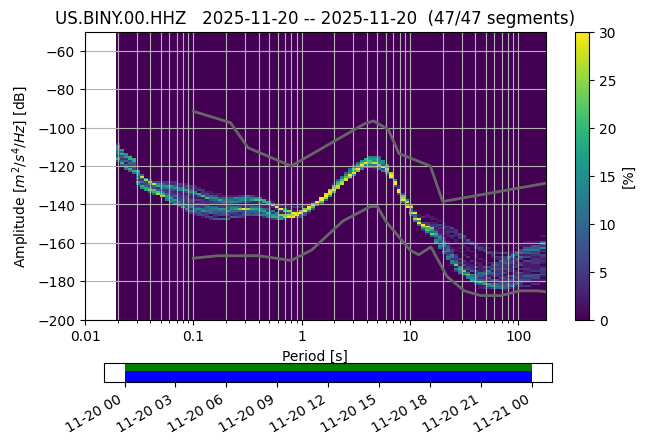

In [ ]:
start_time = UTCDateTime("2025-11-20")
end_time = UTCDateTime("2025-11-21")
# outside Binghamton, NY https://ds.iris.edu/mda/US/BINY/?starttime=1993-08-17&endtime=2599-12-31
# waveform for rural station
waveform_ru = client.get_waveforms(
    network="US",
    station="BINY",
    location="00",
    channel="HHZ",
    starttime=start_time,
    endtime=end_time,
    attach_response=True
)

# inventory for rural station
inv_ru = client.get_stations(
    network="US",
    station="BINY",
    location="00",
    channel="HHZ",
    starttime=start_time,
    endtime=end_time,
    level="response"
)

tr_ru = waveform_ru[0].stats
ppsd_ru = PPSD(tr_ru, metadata=inv_ru)

# Add waveform PPSD
ppsd_ru.add(waveform_ru)

ppsd_ru.plot()

/tmp/ipykernel_19554/1140912702.py:3: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  waveform_stream_ur = client.get_waveforms(


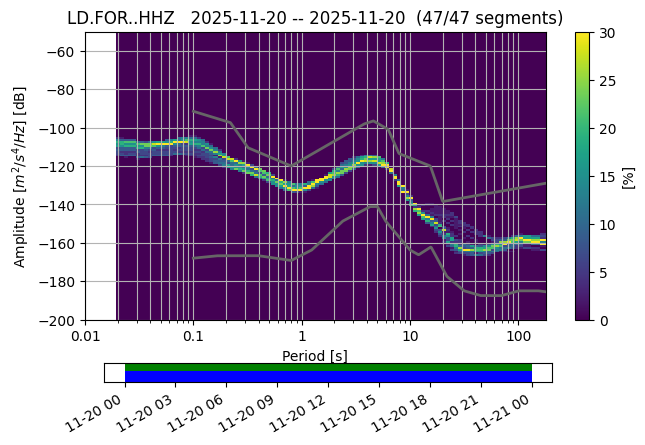

In [ ]:
# Fordham Univ, the bronx, NYC https://ds.iris.edu/mda/LD/FOR/
# waveform urban
waveform_stream_ur = client.get_waveforms(
    network="LD",
    station="FOR",
    location="--",
    channel="HHZ",
    starttime=start_time,
    endtime=end_time,
    attach_response=True
)

# inventory urban
inv_ur = client.get_stations(
    network="LD",
    station="FOR",
    location="--",
    channel="HHZ",
    starttime=start_time,
    endtime=end_time,
    level="response"
)

# ppsd
tr_ur_stats = waveform_stream_ur[0].stats
ppsd_ur = PPSD(tr_ur_stats, metadata=inv_ur)

# waveform to ppsd
ppsd_ur.add(waveform_stream_ur)

ppsd_ur.plot()

My rural station has less noise due to their being less traffic around. And the urban station is in the middle of a major metropolitan area. However the rural station is near a small airport, so that would be causing most of the noise at this station. \
There is more car noise in the urban station, as shown in the higher amplitude to the left side of the PPSD figure. There is still a range of noise on the left side of the rural station's PPSD figure. That could be due to airplanes taking off and landing near the station. \
When comparing the rural surface waves to the urban ones, the urban surface waves are tightly centered on on amplitude, while the rural surface waves have a broader range of amplitudes that they cover. You can see this on the right side of the PPSD figures.

## 3. a) The Sumatra region of Indonesia has experienced 10 M7.5+ earthquakes since 2000. For 4 of the earthquakes, plot the vertical component velocity seismograms at the same station for 1 hour after the origin time. Comment on apparent differences between the seismograms. From the apparent P-wave arrivals, make an estimate of the average P-wave velocity. Next, plot the power spectral densities of these waveforms and comment on any differences you see.

In [ ]:
client_events = Client("USGS")

events = client_events.get_events(
    starttime=UTCDateTime("2009-09-12"),
    endtime=UTCDateTime("2012-04-12"),
    minmagnitude=7.6,
    maxmagnitude=8.6,
)
print(events.__str__(print_all=True))

12 Event(s) in Catalog:
2012-04-11T10:43:10.850000Z |  +0.802,  +92.463 | 8.2  mwc | manual
2012-04-11T08:38:36.720000Z |  +2.327,  +93.063 | 8.6  mw | manual
2011-07-06T19:03:18.260000Z | -29.539, -176.340 | 7.6  mww | manual
2011-03-11T06:25:50.300000Z | +38.058, +144.590 | 7.7  mwc | manual
2011-03-11T06:15:40.280000Z | +36.281, +141.111 | 7.9  mwc | manual
2010-10-25T14:42:22.460000Z |  -3.487, +100.082 | 7.8  mwc | manual
2010-07-23T22:51:11.840000Z |  +6.497, +123.480 | 7.6  mwc | manual
2010-04-06T22:15:01.580000Z |  +2.383,  +97.048 | 7.8  mwc | manual
2009-10-07T22:18:51.240000Z | -12.517, +166.382 | 7.8  mwc | manual
2009-10-07T22:03:14.470000Z | -13.006, +166.510 | 7.7  mww | manual
2009-09-30T10:16:09.250000Z |  -0.720,  +99.867 | 7.6  mwc | manual
2009-09-29T17:48:10.990000Z | -15.489, -172.095 | 8.1  mwc | manual


### Plot vertical component sesimograms

/tmp/ipykernel_19554/3548063275.py:8: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st1 = client.get_waveforms(


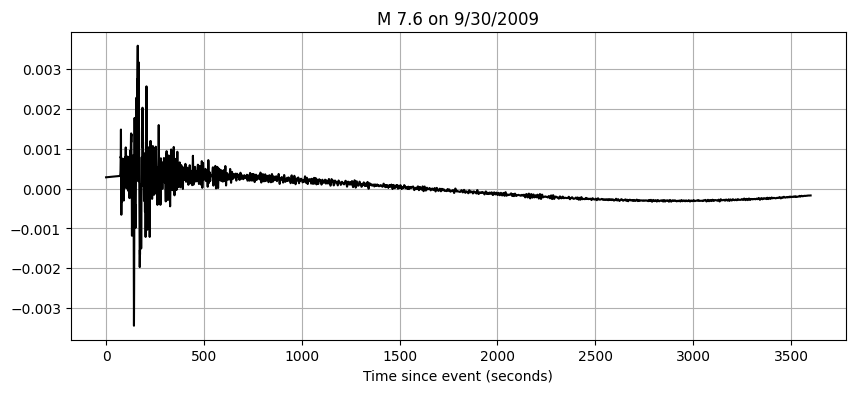

In [ ]:
# station: https://ds.iris.edu/mda/MY/KOM/
#1   2009-09-30T10:16:09.250000Z |  -0.720,  +99.867 | 7.6  mwc | manual  https://earthquake.usgs.gov/earthquakes/eventpage/usp000h237/executive
event1 = events[10]
origin1 = event1.preferred_origin() or event1.origins[0]
magnitude1 = event1.preferred_magnitude() or event1.magnitudes[0]

t1 = origin1.time
st1 = client.get_waveforms(
    network="MY", station="KOM", location="--", channel="BHZ",
    starttime=t1, endtime=t1 + 3600,
    attach_response=True
)
st1.remove_response(output="VEL")
tr1=st1[0]

plt.figure(figsize=(10, 4))
plt.plot(tr1.times(), tr1.data, color="black")
#plt.axvline(70, color="red", linestyle="--", label="P-wave")
plt.xlabel("Time since event (seconds)")
plt.title(f"M 7.6 on 9/30/2009")
plt.grid(True)
plt.show()

/tmp/ipykernel_19554/2307916068.py:9: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st2 = client.get_waveforms(


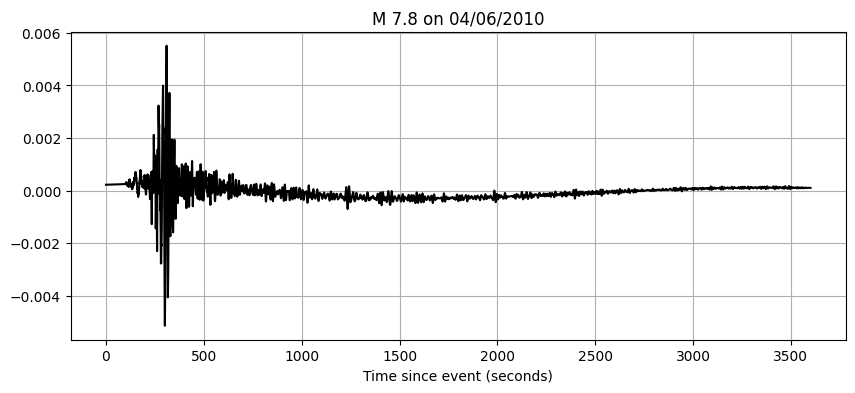

In [ ]:
#2   M 7.8    2010-04-06 22:15:01 (UTC)    2.383°N     97.048°E    31.0 km depth  https://earthquake.usgs.gov/earthquakes/eventpage/usp000hat0/executive
event2 = events[7]
origin2 = event2.preferred_origin() or event2.origins[0]
magnitude2 = event2.preferred_magnitude() or event2.magnitudes[0]

client = Client("EARTHSCOPE")

t2 = origin2.time
st2 = client.get_waveforms(
    network="MY", station="KOM", location="--", channel="BHZ",
    starttime=t2, endtime=t2 + 3600, attach_response=True
)

st2.remove_response(output="VEL")
tr2=st2[0]

plt.figure(figsize=(10, 4))
plt.plot(tr2.times(), tr2.data, color="black")
#plt.axvline(100, color="red", linestyle="--", label="P-wave")
plt.xlabel("Time since event (seconds)")
plt.title(f"M 7.8 on 04/06/2010")
plt.grid(True)
plt.show()

/tmp/ipykernel_19554/4084132482.py:9: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st3 = client.get_waveforms(


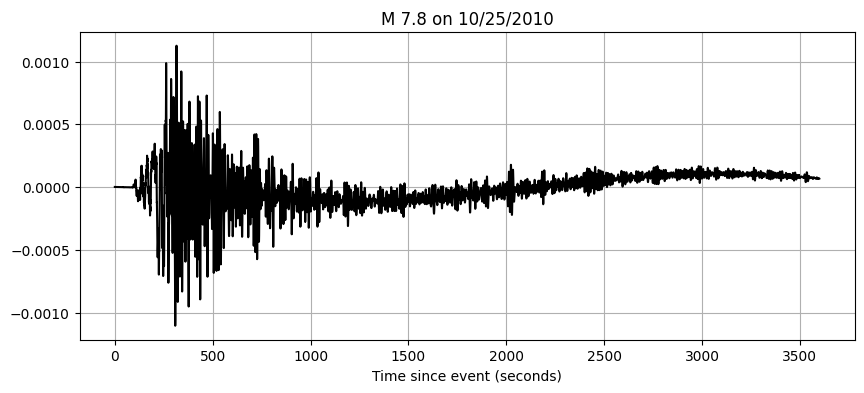

In [ ]:
# 2010-10-25T14:42:22.460000Z |  -3.487, +100.082 | 7.8  mwc | manual   https://earthquake.usgs.gov/earthquakes/eventpage/usp000hnj4/executive
event3 = events[5]
origin3 = event3.preferred_origin() or event3.origins[0]
magnitude3 = event3.preferred_magnitude() or event3.magnitudes[0]

client = Client("EARTHSCOPE")

t3 = origin3.time
st3 = client.get_waveforms(
    network="MY", station="KOM", location="--", channel="BHZ",
    starttime=t3, endtime=t3 + 3600, attach_response=True
)

st3.remove_response(output="VEL")
tr3=st3[0]

plt.figure(figsize=(10, 4))
plt.plot(tr3.times(), tr3.data, color="black")
#plt.axvline(90, color="red", linestyle="--", label="P-wave")
plt.xlabel("Time since event (seconds)")
plt.title(f"M 7.8 on 10/25/2010")
plt.grid(True)
plt.show()

/tmp/ipykernel_19554/349179842.py:9: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st4 = client.get_waveforms(


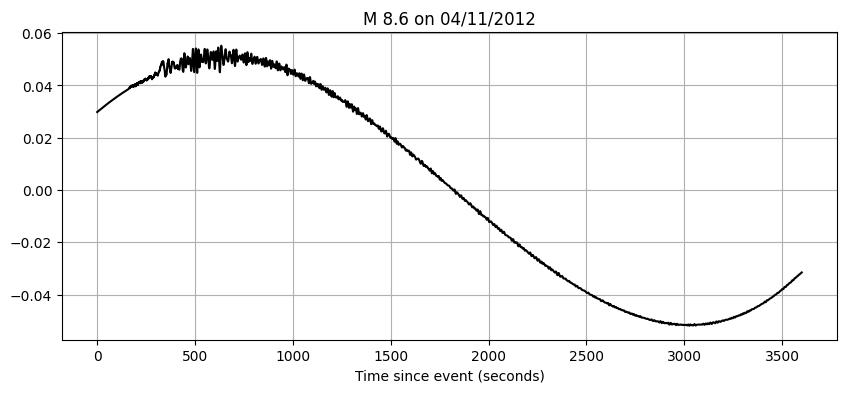

In [ ]:
# 2012-04-11T08:38:36.720000Z |  +2.327,  +93.063 | 8.6  mw | manual    https://earthquake.usgs.gov/earthquakes/eventpage/official20120411083836720_20/executive
event4 = events[1]
origin4 = event4.preferred_origin() or event4.origins[0]
magnitude4 = event4.preferred_magnitude() or event4.magnitudes[0]

client = Client("EARTHSCOPE")

t4 = origin4.time
st4 = client.get_waveforms(
    network="MY", station="KOM", location="--", channel="BHZ",
    starttime=t4, endtime=t4 + 3600, attach_response=True
)

st4.remove_response(output="VEL")
tr4=st4[0]

plt.figure(figsize=(10, 4))
plt.plot(tr4.times(), tr4.data, color="black")
#plt.axvline(165, color="red", linestyle="--", label="P-wave")
plt.xlabel("Time since event (seconds)")
plt.title(f"M 8.6 on 04/11/2012")
plt.grid(True)
plt.show()

/tmp/ipykernel_19554/2453796692.py:5: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[0].legend()
/tmp/ipykernel_19554/2453796692.py:9: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[1].legend()
/tmp/ipykernel_19554/2453796692.py:13: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[2].legend()
/tmp/ipykernel_19554/2453796692.py:17: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  axs[3].legend()


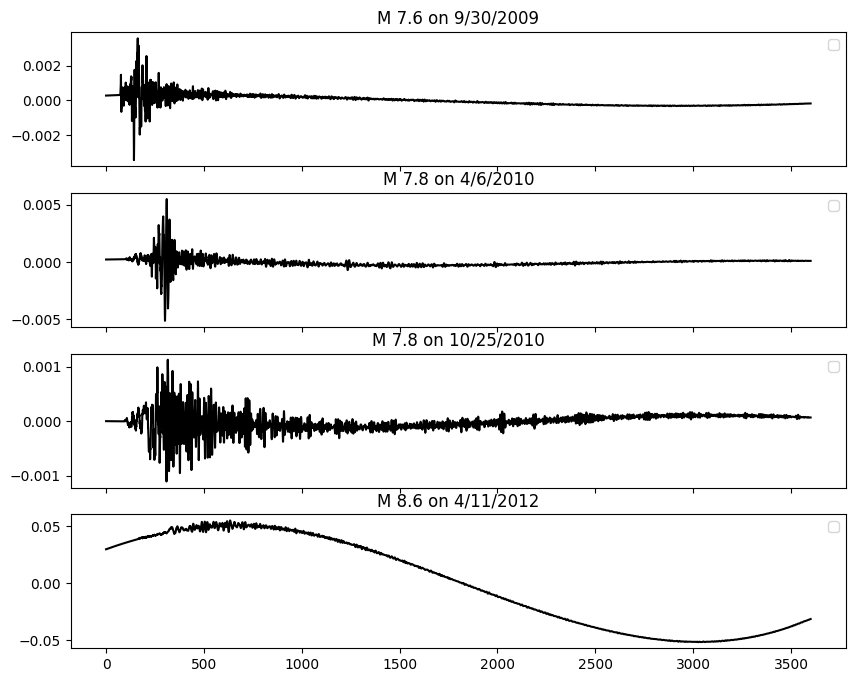

In [ ]:
fig,axs = plt.subplots(4, 1, figsize=(10, 8), sharex=True)

axs[0].plot(tr1.times(), tr1.data, color="black")
axs[0].set_title("M 7.6 on 9/30/2009")
axs[0].legend()

axs[1].plot(tr2.times(), tr2.data, color="black")
axs[1].set_title("M 7.8 on 4/6/2010")
axs[1].legend()

axs[2].plot(tr3.times(), tr3.data, color="black")
axs[2].set_title("M 7.8 on 10/25/2010")
axs[2].legend()

axs[3].plot(tr4.times(), tr4.data, color="black")
axs[3].set_title("M 8.6 on 4/11/2012")
axs[3].legend()

The arrival times of the different P-waves seem to be fairly similar. However, the strength of the waves varies. \
The strongest quake, the M 8.6 in 2012, seems to have the weakest record at this station. This could be due to the distance between the two being the greates of the four earthquakes. \
For the two M 7.8's in 2010, one has a much stronger recording, that being the one in April, which has a much larger peak. The could be due to the origin location of the earthquake, they both occured in separate parts of the region. However, they both seem to have occured around they same distance away. The October quake could have just had weaker shaking than the April one. \
Finally, the M 7.6 in 2009 has a moderate peak. It is not as strong as some of the other quakes but still considerable. The epicenter of the 2009 earthquake was the closest of the four quakes to the station.

### From the apparent P-wave arrivals, make an estimate of the average P-wave velocity

In [ ]:
pwave1=70.0
pwave2=100.0
pwave3=90.0
pwave4=165.0

station = {"latitude": 1.7922, "longitude": 103.846703}

eq1 = {"latitude": -0.720, "longitude": 99.867}
eq2 = {"latitude": 2.383, "longitude": 97.048}
eq3 = {"latitude": 3.487, "longitude": 100.082}
eq4 = {"latitude": 2.327, "longitude": 93.063}

distance1 = gps2dist_azimuth(eq1["latitude"], eq1["longitude"], station["latitude"], station["longitude"])[0] / 1000
vel1 = distance1/pwave1

distance2 = gps2dist_azimuth(eq2["latitude"], eq2["longitude"], station["latitude"], station["longitude"])[0] / 1000
vel2 = distance2/pwave2

distance3 = gps2dist_azimuth(eq3["latitude"], eq3["longitude"], station["latitude"], station["longitude"])[0] / 1000
vel3 = distance3/pwave3

distance4 = gps2dist_azimuth(eq4["latitude"], eq4["longitude"], station["latitude"], station["longitude"])[0] / 1000
vel4 = distance4/pwave4

print(f"{'Event':<30}{'P-wave velocity (km/s)'}")
print(f"{'M 7.6 9/30/2009':<30}{vel1:>15.2f}")
print(f"{'M 7.8 4/06/2010':<30}{vel2:>15.2f}")
print(f"{'M 7.8 10/25/2010':<30}{vel3:>15.2f}")
print(f"{'M 8.6 4/11/2012':<30}{vel4:>15.2f}")

Event                         P-wave velocity (km/s)
M 7.6 9/30/2009                          7.47
M 7.8 4/06/2010                          7.59
M 7.8 10/25/2010                         5.10
M 8.6 4/11/2012                          7.28


### Next, plot the power spectral densities of these waveforms and comment on any differences you see.

/tmp/ipykernel_19554/919858258.py:1: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st_1 = client.get_waveforms(


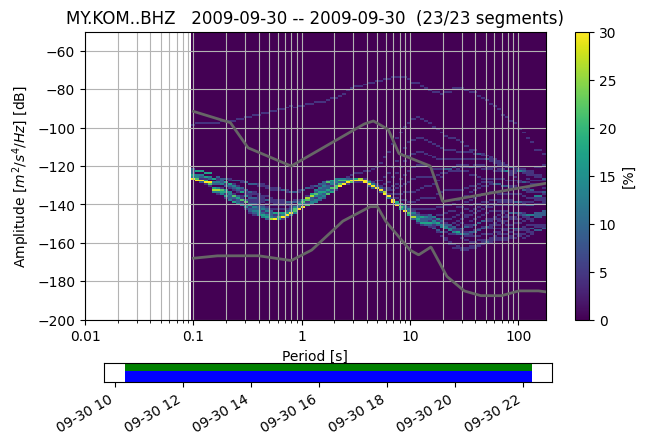

In [ ]:
st_1 = client.get_waveforms(
    network="MY",
    station="KOM",
    location="--",
    channel="BHZ",
    starttime=t1,
    endtime=t1 + 3600*12,
    attach_response=True
)

st_1_cp = st_1.copy()
st_1_cp.remove_response(output="VEL")

inv_1 = client.get_stations(
    network="MY",
    station="KOM",
    location="--",
    channel="BHZ",
    starttime=t1,
    endtime=t1 + 3600*12,
    level="response"
)

tr_1 = st_1_cp[0]
ppsd_1 = PPSD(st_1_cp[0].stats, metadata=inv_1)

# Add waveform PPSD
ppsd_1.add(st_1)

ppsd_1.plot()

/tmp/ipykernel_19554/874679044.py:1: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st_2 = client.get_waveforms(


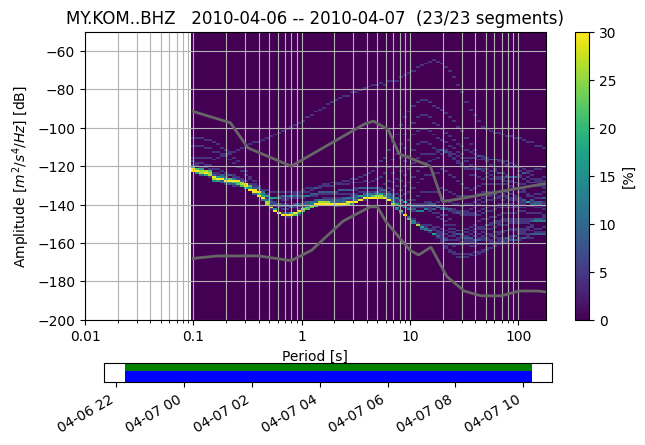

In [ ]:
st_2 = client.get_waveforms(
    network="MY",
    station="KOM",
    location="--",
    channel="BHZ",
    starttime=t2,
    endtime=t2 + 3600*12,
    attach_response=True
)

st_2_cp = st_2.copy()
st_2_cp.remove_response(output="VEL")

inv_2 = client.get_stations(
    network="MY",
    station="KOM",
    location="--",
    channel="BHZ",
    starttime=t2,
    endtime=t2 + 3600*12,
    level="response"
)

tr_2 = st_2_cp[0]
ppsd_2 = PPSD(st_2_cp[0].stats, metadata=inv_2)

# Add waveform PPSD
ppsd_2.add(st_2)

ppsd_2.plot()

/tmp/ipykernel_19554/1354210869.py:1: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st_3 = client.get_waveforms(


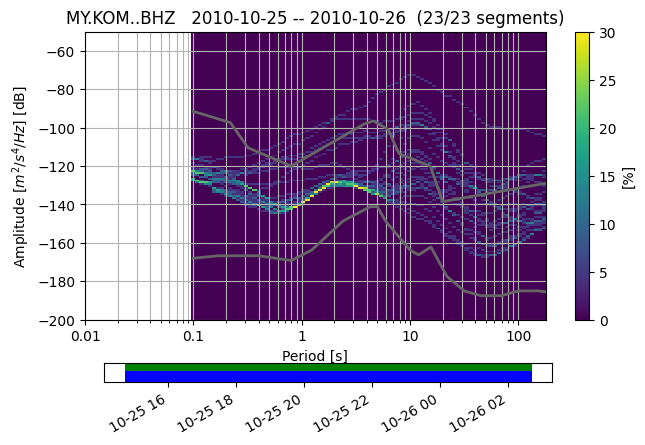

In [ ]:
st_3 = client.get_waveforms(
    network="MY",
    station="KOM",
    location="--",
    channel="BHZ",
    starttime=t3,
    endtime=t3 + 3600*12,
    attach_response=True
)

st_3_cp = st_3.copy()
st_3_cp.remove_response(output="VEL")

inv_3 = client.get_stations(
    network="MY",
    station="KOM",
    location="--",
    channel="BHZ",
    starttime=t3,
    endtime=t3 + 3600*12,
    level="response"
)

tr_3 = st_3_cp[0]
ppsd_3 = PPSD(st_3_cp[0].stats, metadata=inv_3)

# Add waveform PPSD
ppsd_3.add(st_3)

ppsd_3.plot()

/tmp/ipykernel_19554/3498810852.py:1: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st_4 = client.get_waveforms(


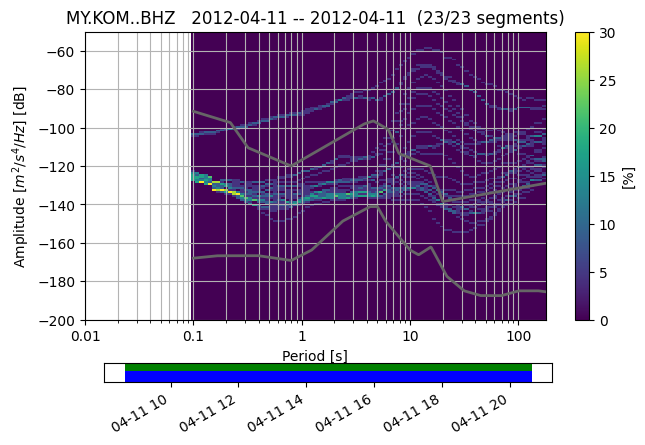

In [ ]:
st_4 = client.get_waveforms(
    network="MY",
    station="KOM",
    location="--",
    channel="BHZ",
    starttime=t4,
    endtime=t4 + 3600*12,
    attach_response=True
)

st_4_cp = st_4.copy()
st_4_cp.remove_response(output="VEL")

inv_4 = client.get_stations(
    network="MY",
    station="KOM",
    location="--",
    channel="BHZ",
    starttime=t4,
    endtime=t4 + 3600*12,
    level="response"
)

tr_4 = st_4_cp[0]
ppsd_4 = PPSD(st_4_cp[0].stats, metadata=inv_4)

# Add waveform PPSD
ppsd_4.add(st_4)

ppsd_4.plot()

**COMMENT ON ANY DIFFERENCES YOU SEE IN PSD** \
The 2009 M 7.6 earthquake had a lot of noise in its higher periods, while its lower periods still seemed to be tightly bound. \
For the April 2010 earthquake, there was less noise than the 2009 earthquake at the lower periods, but the higher periods had much more noise than the 2009 earthquake. This could be due to the nature of the body waves that arrived at the station, and the strength of the initial earthquake being greater than the 2009 earthquake. \
For the October 2010 Earthquake, there was even more noise than the previous two earthquakes at the high periods. There was also more noise than the previous two earthquakes at the lower peiod. For the noise at the higher range of the period, this could be due to the earthquake having a longer period of shaking, which can be seen in the seismogram for the event. \
Finally, the 2012 M 8.6 had by far the most noise throughout the PPSD. This could be due to the strenth of the earthquake.


## 3. b) For one of the Sumatra earthquakes, find vertical component velocity seismograms for 4 different stations at different source distances and plot them as a function of distance from the source in degrees. Make an estimate of the average velocity here based on the P wave arrivals.

In [ ]:
# 2012-04-11T08:38:36.720000Z |  +2.327,  +93.063 | 8.6  mw | manual    https://earthquake.usgs.gov/earthquakes/eventpage/official20120411083836720_20/executive
# station 1: https://ds.iris.edu/mda/MY/KOM/ - STATION from 3A
# station 2: https://ds.iris.edu/mda/MY/KSM/
# station 3: https://ds.iris.edu/mda/PS/PSI/
# station 4: https://ds.iris.edu/mda/MY/KUM/

earthquake3b = { "origin_time": UTCDateTime("2012-04-11T08:38:36"), "latitude":2.327, "longitude":93.063, "magnitude": 8.6}

stations = [
    {"network":"MY", "station":"KSM", "location":"--", "channel":"BHZ", "latitude": 1.4733, "longitude": 110.308296},
    {"network":"MY", "station":"KUM", "location":"--", "channel":"BHZ", "latitude": 5.2902, "longitude": 100.6492},
    {"network":"MY", "station":"KOM", "location":"--", "channel":"BHZ", "latitude": 1.3039, "longitude": 97.5755},
    {"network":"PS", "station":"PSI", "location":"--", "channel":"BHZ", "latitude": 5.2288, "longitude": 96.947197},
]


In [ ]:
#distances
distances = []
traces = []

dist_1 = gps2dist_azimuth(earthquake3b["latitude"], earthquake3b["longitude"], stations[0]["latitude"], stations[0]["longitude"])
dist_1_deg = kilometer2degrees(dist_1[0]/1000.00)
distances.append(dist_1_deg)

dist_2 = gps2dist_azimuth(earthquake3b["latitude"], earthquake3b["longitude"], stations[1]["latitude"], stations[1]["longitude"])
dist_2_deg = kilometer2degrees(dist_2[0]/1000.00)
distances.append(dist_2_deg)

dist_3 = gps2dist_azimuth(earthquake3b["latitude"], earthquake3b["longitude"], stations[2]["latitude"], stations[2]["longitude"])
dist_3_deg = kilometer2degrees(dist_3[0]/1000.00)
distances.append(dist_3_deg)

dist_4 = gps2dist_azimuth(earthquake3b["latitude"], earthquake3b["longitude"], stations[3]["latitude"], stations[3]["longitude"])
dist_4_deg = kilometer2degrees(dist_4[0]/1000.00)
distances.append(dist_4_deg)

print(distances)

for station in stations:
  try:
    #wavedata
    st = client.get_waveforms(
        network=station["network"],
        station=station["station"],
        location=station["location"],
        channel=station["channel"],
        starttime=earthquake3b["origin_time"],
        endtime=earthquake3b["origin_time"] + 3600,
        attach_response=True
    )

    st.remove_response(output="VEL")
    traces.append((station["station"], st[0]))
  except Exception as e:
    print(f"Error for station {station['station']}: {e}")

[17.275824766205062, 8.130006482244369, 4.6284457706197015, 4.835266528027864]


/tmp/ipykernel_19554/1831744185.py:26: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st = client.get_waveforms(
/tmp/ipykernel_19554/1831744185.py:26: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st = client.get_waveforms(
/tmp/ipykernel_19554/1831744185.py:26: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st = client.get_waveforms(
/tmp/ipykernel_19554/1831744185.py:26: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st = client.get_waveforms(


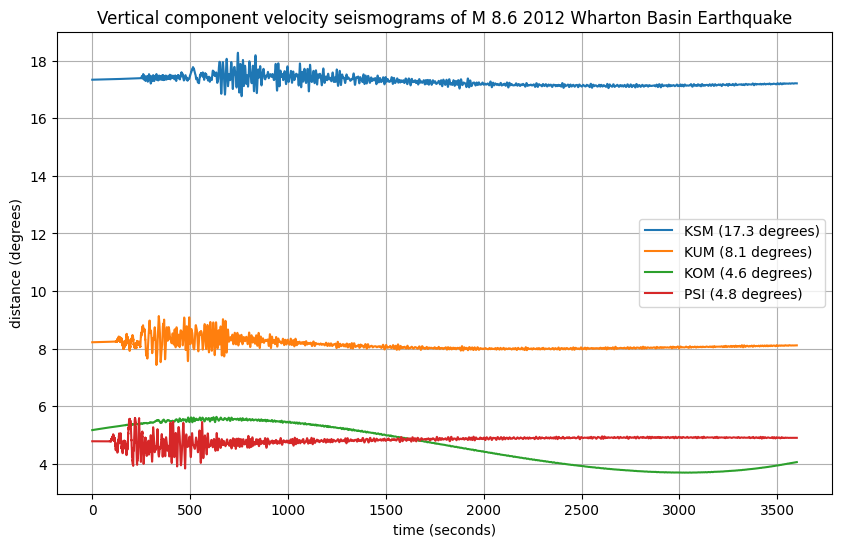

In [ ]:
plt.figure(figsize=(10, 6))
for station, tr in traces:
    plt.plot(tr.times(),
             tr.data / max(abs(tr.data)) + distances[traces.index((station, tr))],
             label=f"{station} ({distances[traces.index((station, tr))]:.1f} degrees)"
             )
#plt.axvline(270, color="red", linestyle="--", label="P-wave")
plt.xlabel("time (seconds)")
plt.ylabel("distance (degrees)")
plt.legend()
plt.title("Vertical component velocity seismograms of M 8.6 2012 Wharton Basin Earthquake")
plt.grid()
plt.show()

In [ ]:
#estimate of average velocity based on p wave arrivals
p_time = [250, 120, 270, 90]
p_wave_dist = distances
p_wave_vel = [d * 111 / t for d, t in zip(p_wave_dist, p_time)]

avg_vel = sum(p_wave_vel) / len(p_wave_vel)
print(f"avg vel: {avg_vel} m/s")

avg vel: 5.764255765078944 m/s


## 3. c) For one of your waveforms, apply a high-pass filter at 0.01 and 1 Hz and plot the results. Label any phase arrivals that you may see.

/tmp/ipykernel_19554/2353383069.py:4: ObsPyDeprecationWarning: attach_response is deprecated and will be removed in a future release. Use remove_response() instead.
  st3c = client.get_waveforms(


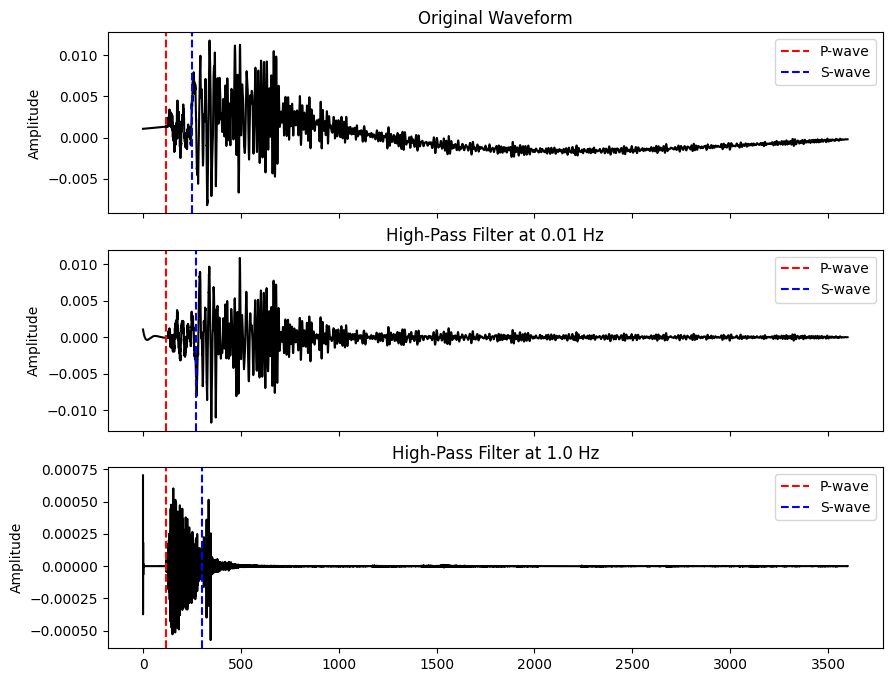

In [ ]:
# station: https://ds.iris.edu/mda/MY/KUM/
# from M 8.6 2012 Earthquake - event of 3b

st3c = client.get_waveforms(
    network="MY",
    station="KUM",
    location="--",
    channel="BHZ",
    starttime=earthquake3b["origin_time"],
    endtime=earthquake3b["origin_time"] + 3600,
    attach_response=True
)

st3c.remove_response(output="VEL")

tr3c = st3c[0]

trog = tr3c.copy() # original waveform
tr1 = tr3c.copy().filter("highpass", freq=1.0) # high pass filter at 1.0 hz
tr01 = tr3c.copy().filter("highpass", freq=0.01) # high pass filter at 0.01 Hz


fig,axs = plt.subplots(3, 1, figsize=(10, 8), sharex=True)

axs[0].plot(trog.times(), trog.data, color="black")
axs[0].axvline(120, color="red", linestyle="--", label="P-wave")
axs[0].axvline(250, color='blue', linestyle='--', label="S-wave")
axs[0].set_title("Original Waveform")
axs[0].set_ylabel("Amplitude")
axs[0].legend()

axs[1].plot(tr01.times(), tr01.data, color="black")
axs[1].axvline(120, color="red", linestyle="--", label="P-wave")
axs[1].axvline(270, color='blue', linestyle='--', label="S-wave")
axs[1].set_title("High-Pass Filter at 0.01 Hz")
axs[1].set_ylabel("Amplitude")
axs[1].legend()

axs[2].plot(tr1.times(), tr1.data, color="black")
axs[2].axvline(120, color="red", linestyle="--", label="P-wave")
axs[2].axvline(300, color='blue', linestyle='--', label="S-wave")
axs[2].set_title("High-Pass Filter at 1.0 Hz")
axs[2].set_ylabel("Amplitude")
axs[2].legend()
